# Explanation Evaluation
To evaluate the performance of my explanations, I need to compute the AUROC curve. I will do that for three cases:
- Token-Level Probabilities (baseline)
- Explanations Similarity
- Random Forest - Explanations Similarity + Linter Features

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

In [45]:
ground_truth = pd.read_csv('datasets/evaluation_python_solutions_1.csv')

In [46]:
ground_truth.shape

(1160, 14)

In [47]:
ground_truth.head()

,problem_title,code_line,is_readable,correct_naming,has_good_length,is_logic_straightforward,is_consistently_formatted,avoid_side_effects,dry,respect_language_practice,error_handling,extreme_error,sum_criteria,good
0,Sports Rank,def read_input():,1,0,1,1,1,1,1,1,1,0,8,1
1,Sports Rank,import sys,1,1,1,1,1,1,1,0,1,0,8,1
2,Sports Rank,input = sys.stdin.read,1,0,1,1,1,1,1,0,1,0,7,0
3,Sports Rank,data = input().split(),1,0,1,1,1,1,1,1,0,0,7,0
4,Sports Rank,index = 0,1,1,1,1,1,1,1,1,1,0,9,1


In [49]:
ground_truth_classes = list(map(int, list(ground_truth['good'])))

In [56]:
def plot_roc_curve(fpr, tpr):
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, 
             label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Baseline')
    plt.legend(loc='lower right')
    plt.show()
    
    print(f"AUROC: {roc_auc:.4f}")

In [51]:
def get_auroc(ground_truth, predicted_probs):
    fpr, tpr, thresholds = roc_curve(ground_truth, predicted_probs)
    plot_roc_curve(fpr, tpr)

## Baseline

In [37]:
baseline_probabilities = pd.read_csv('datasets/probabilities_python_final.csv')

In [39]:
baseline_probabilities = baseline_probabilities[baseline_probabilities['line_number'] != 0]
baseline_probabilities = baseline_probabilities[baseline_probabilities['line_text'].str.strip() != '']
baseline_probabilities = baseline_probabilities[~baseline_probabilities['line_text'].str.strip().str.startswith('#')]
baseline_probabilities

,title,line_number,line_text,token_prob
1,Sports Rank,1,def read_input():\n,0.667149
2,Sports Rank,2,import sys\n,0.972428
3,Sports Rank,3,input = sys.stdin.read\n,0.992203
4,Sports Rank,4,data = input().split()\n,0.992855
6,Sports Rank,6,index = 0\n,0.939398
...,...,...,...,...
1353,New Distinct Substrings,39,string = data[index]\n,0.865940
1354,New Distinct Substrings,40,index += 1\n,0.921482
1355,New Distinct Substrings,41,results.append(count_distinct_substrings(s...,0.955230
1356,New Distinct Substrings,43,for result in results:\n,0.999838


In [41]:
baseline_probabilities.shape

(1160, 4)

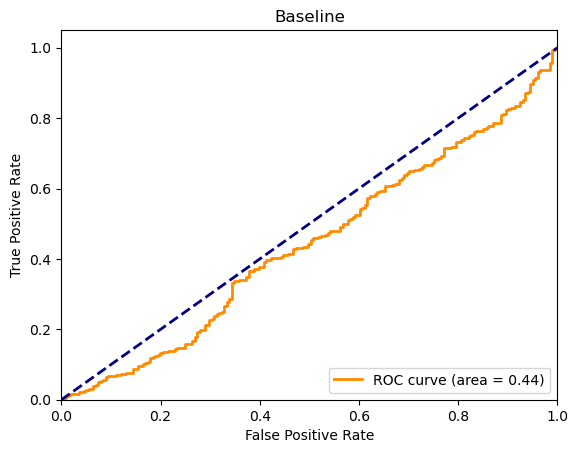

AUROC: 0.4431


In [57]:
get_auroc(ground_truth_classes, list(baseline_probabilities['token_prob']))